In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Arc
import matplotlib.cm as cm 
import seaborn as sns

In [ ]:
#Gets Dataset
lebron_df = pd.read_csv("/Users/eliasnicolas/Desktop/Data_Science_Projects/Lebron_shot_chart/1_lebron_james_shot_chart_1_2023.csv")

#Renaming shot_type and result
lebron_df['shot_type'] = lebron_df['shot_type'].replace({2:'2-point shot', 3: '3-point shot'})
lebron_df['result'] = lebron_df['result'].replace({True: 'Made', False: 'Missed'})

#Printing information
lebron_df.head(1535)
#print(lebron_df.notnull)

/var/folders/c3/chj3vg0d4xd3mlyjdyrp7p_r0000gn/T/ipykernel_72323/3194784045.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='shot_type', data=lebron_df, palette='viridis')


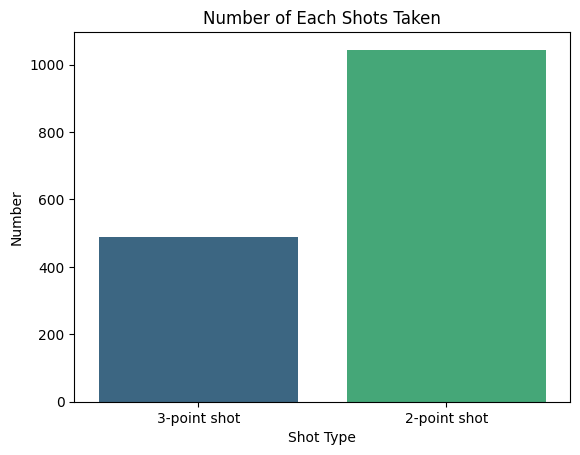

In [21]:
#Making a bar graph
sns.countplot(x='shot_type', data=lebron_df, palette='viridis')
plt.title("Number of Each Shots Taken")
plt.xlabel("Shot Type")
plt.ylabel("Number")
plt.show()

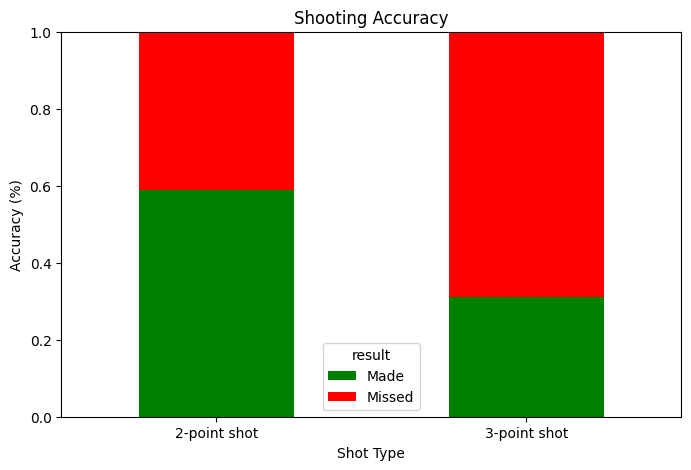

In [6]:
#Bar Chart 2: Shooting Accuracy by Shot Type

#Group by shot type and result, calculate percentage
accuracy_by_type = lebron_df.groupby('shot_type')['result'].value_counts(normalize=True).unstack().fillna(0)

#Plot as a bar chart
accuracy_by_type[['Made', 'Missed']].plot(kind='bar',
                                          stacked=True,
                                          color=['green', 'red'],
                                          figsize=(8,5))
plt.title("Shooting Accuracy")
plt.xlabel("Shot Type")
plt.ylabel("Accuracy (%)")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.show()

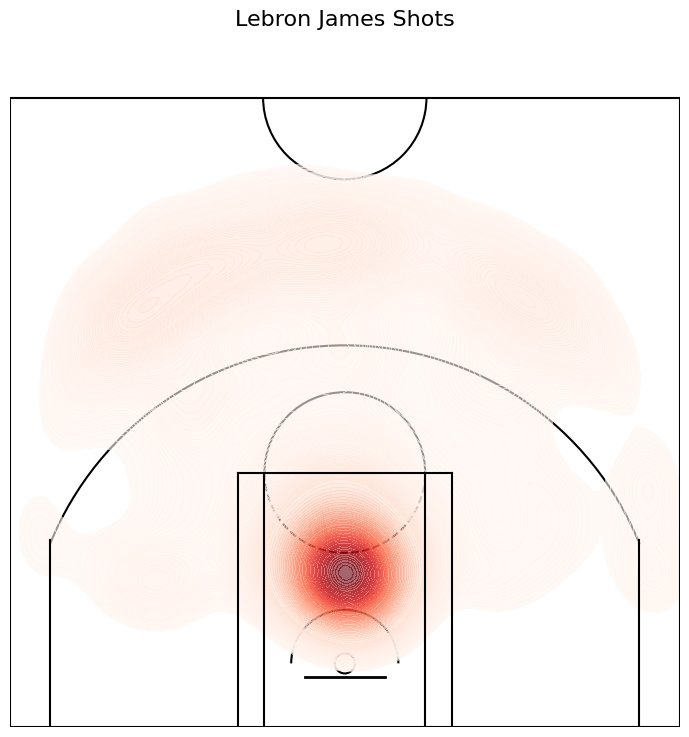

In [10]:
def convert_coords(df):
    df['court_x']=df['left']-240
    df['court_y']=df['top']

    return df
lebron_df=convert_coords(lebron_df)

# --- Court Drawing Function ---

def draw_nba_court(axis=None):
    """
    Draws an NBA halfcourt using matplotlib primitives.

    Args:
        axis (matplotlib axis): Optional axis to draw on. Creates one if not provided.

    Returns:
        fig, axis: Figure and axis with the court drawn
    """
    if axis is None:
        fig = plt.figure(figsize=(9, 9))
        axis = fig.add_subplot(111, aspect='auto')
    else:
        fig = None

    # --- Court Outline (Baseline, Sidelines, Halfcourt Line) ---
    axis.plot([-250, 250], [-47.5, -47.5], 'k-')     # Baseline
    axis.plot([-250, -250], [-47.5, 422.5], 'k-')    # Left sideline
    axis.plot([250, 250], [-47.5, 422.5], 'k-')      # Right sideline
    axis.plot([-250, 250], [422.5, 422.5], 'k-')     # Halfcourt line

    # --- Backboard ---
    axis.plot([-30, 30], [-10, -10], 'k-', lw=2)

    # --- Paint / Lane ---
    axis.plot([-80, -80], [-47.5, 142.5], 'k-')
    axis.plot([80, 80], [-47.5, 142.5], 'k-')
    axis.plot([-60, -60], [-47.5, 142.5], 'k-')
    axis.plot([60, 60], [-47.5, 142.5], 'k-')
    axis.plot([-80, 80], [142.5, 142.5], 'k-')     # Free throw line

    # --- Hoop and Restricted Area ---
    hoop = Arc((0, 0), 15, 15, theta1=0, theta2=360, lw=1.5, color='black')
    restricted = Arc((0, 0), 80, 80, theta1=0, theta2=180, lw=1.5, color='black')
    axis.add_patch(hoop)
    axis.add_patch(restricted)

    # --- Free Throw Circle ---
    axis.add_patch(Arc((0, 142.5), 120, 120, theta1=0, theta2=180, lw=1.5, color='black'))     # Top half
    axis.add_patch(Arc((0, 142.5), 120, 120, theta1=180, theta2=360, lw=1.5, linestyle='--', color='black'))  # Bottom half (dashed)

    # --- 3-Point Lines ---
    axis.plot([-220, -220], [-47.5, 92.5], 'k-')     # Left corner 3
    axis.plot([220, 220], [-47.5, 92.5], 'k-')       # Right corner 3
    axis.add_patch(Arc((0, 0), 475, 475, theta1=22, theta2=158, lw=1.5, color='black'))   # 3-pt arc

    # --- Halfcourt Circle ---
    axis.add_patch(Arc((0, 422.5), 122, 122, theta1=180, theta2=360, lw=1.5, color='black'))

    # --- Axis Settings ---
    axis.set_xlim(-250, 250)
    axis.set_ylim(-47.5, 470)
    axis.set_aspect(1)     # Equal aspect ratio
    axis.axis('off')       # Hide axes

    return fig, axis

fig, ax = plt.subplots(figsize=(9,9))

draw_nba_court(ax)

kde = sns.kdeplot(
    x=lebron_df['court_x'],
    y=lebron_df['court_y'],
    fill=True,
    cmap='Reds',
    bw_adjust=0.8,
    alpha=0.6,
    levels=100,
    thresh=0.05,
    ax=ax
)
plt.title("Lebron James Shots", fontsize=16)
plt.show()
